In [126]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Configuração Estética
# plt.style.use('ggplot')
#plt.rcParams['figure.figsize'] = (14, 8)

#Dados (Johns Hopkins University)
# URL = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"
# df = pd.read_csv(URL)

#comentar sobre a origem dos dados aqui
df = pd.read_csv('time_series_covid19_confirmed_global.csv')

# 2. Filtrar França (Soma das províncias)
france_data = df[df['Country/Region'] == 'France'].iloc[:, 4:].sum(axis=0)
france_data.index = pd.to_datetime(france_data.index, errors='coerce')

# 3. Vetores Principais
y_real_acc = france_data.values.astype(float) # Casos Totais (C)
x_days = np.arange(len(y_real_acc))
N = 67_500_000 

# Calculamos novos casos (Hoje - Ontem)
y_daily = np.diff(y_real_acc, prepend=0)

# ESTIMATIVA DE CASOS ATIVOS REAIS (Proxy para comparação)
# Assumimos que Ativos = Soma dos novos casos dos últimos 8 dias
y_real_active = pd.Series(y_daily).rolling(window=10).sum().fillna(0).values

print(f"Dados carregados: {len(x_days)} dias de pandemia.")
print(f"Total acumulado final: {y_real_acc[-1]:,.0f}")

print(y_real_acc[0])

Dados carregados: 1143 dias de pandemia.
Total acumulado final: 39,866,718
0.0


C:\Users\pedro\AppData\Local\Temp\ipykernel_7472\2012503586.py:19: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  france_data.index = pd.to_datetime(france_data.index, errors='coerce')


In [127]:

def sir_discrete(t, beta, gamma, return_full=False):
    
    S = np.zeros(len(t))
    I = np.zeros(len(t))
    R = np.zeros(len(t))
    
    
    I[0] = max(y_real_acc[0], 1)
    S[0] = N - I[0]
    
    for i in range(len(t) - 1):
        
        new_inf = (beta * S[i] * I[i]) / N
        new_rec = gamma * I[i]
        
        S[i+1] = max(0, S[i] - new_inf)
        I[i+1] = max(0, I[i] + new_inf - new_rec)
        R[i+1] = R[i] + new_rec
        
    if return_full: return S, I, R, (I + R)
    return I + R


def sirsd_discrete(t, beta, gamma, xi, mu, return_full=False):
    
    S = np.zeros(len(t))
    I = np.zeros(len(t))
    R = np.zeros(len(t))
    D = np.zeros(len(t)) # --- NOVO: Array para Mortos ---
    C = np.zeros(len(t))
    
    I[0] = max(y_real_acc[0], 1)
    C[0] = max(y_real_acc[0], 1)
    S[0] = N - I[0]
    
    for i in range(len(t) - 1):

        new_inf = (beta * S[i] * I[i]) / N
        new_rec = gamma * I[i]
        new_death = mu * I[i]     # --- NOVO: Calculamos quem morreu hoje ---
        new_susc = xi * R[i]      # Perda de imunidade (só dos vivos/recuperados)
        
        # Atualização das caixas
        S[i+1] = max(0, S[i] - new_inf + new_susc)
        
        # Infectados perdem gente por cura E por morte
        I[i+1] = max(0, I[i] + new_inf - new_rec - new_death) 
        
        R[i+1] = max(0, R[i] + new_rec - new_susc)
        
        # Os mortos apenas acumulam (é um "estado absorvente", ninguém sai dele)
        D[i+1] = D[i] + new_death 
        
        C[i+1] = C[i] + new_inf
        
    if return_full: return S, I, R, D, C # Retorna D também
    return C

num_nodes = 5 # Nós de controle para o Beta Variável
x_nodes = np.linspace(0, len(x_days), num_nodes)


def sirs_dynamic_discrete(t, gamma, xi, mu, *betas_array, return_full=False):
    # Inicializa arrays (agora inclui D para Mortos)
    S = np.zeros(len(t))
    I = np.zeros(len(t))
    R = np.zeros(len(t))
    D = np.zeros(len(t)) # --- NOVO: Acumulado de óbitos ---
    C = np.zeros(len(t))
    
    # Inicialização bruta (mantendo sua lógica original)
    I[0] = next((x for x in y_daily if x > 0), 1.0)
    C[0] = y_real_acc[0] if y_real_acc[0] > 0 else I[0]
    S[0] = N - I[0]
    # D[0] assume-se 0, a menos que você tenha dados prévios de óbitos
    
    # Loop temporal
    for i in range(len(t) - 1):
        
        # --- Lógica de Degrau (Step) para o Beta ---
        # Descobre qual índice de intervalo o dia 'i' pertence
        idx = np.searchsorted(x_nodes, i, side='right') - 1
        
        # Proteção de índice
        idx = max(0, min(idx, len(betas_array) - 1))
        
        # Seleciona o Beta vigente naquele dia
        beta_t = betas_array[idx]
        # ---------------------------------------------
        
        # --- CÁLCULO DOS FLUXOS DIÁRIOS ---
        
        # 1. Novas infecções (Transmissão)
        new_inf = (beta_t * S[i] * I[i]) / N
        
        # 2. Recuperação (Saída para R)
        new_rec = gamma * I[i]
        
        # 3. Mortes (Saída para D) --- NOVO ---
        new_death = mu * I[i]
        
        # 4. Perda de Imunidade (Volta para S)
        new_susc = xi * R[i]
        
        # --- ATUALIZAÇÃO DOS ESTADOS ---
        
        # Suscetíveis: Perdem para infecção, ganham da perda de imunidade
        S[i+1] = max(0, S[i] - new_inf + new_susc)
        
        # Infectados: Ganham novos, perdem para cura E para morte
        I[i+1] = max(0, I[i] + new_inf - new_rec - new_death)
        
        # Recuperados: Ganham da cura, perdem para suscetibilidade
        # (Nota: Mortos não perdem imunidade, eles saíram do sistema dinâmico)
        R[i+1] = max(0, R[i] + new_rec - new_susc)
        
        # Mortos: É um estado acumulativo (absorvente). Ninguém sai daqui.
        D[i+1] = D[i] + new_death
        
        # Casos Acumulados (apenas para ajuste de curva)
        C[i+1] = C[i] + new_inf
        
    if return_full: 
        return S, I, R, D, C # Agora retorna D também
    return C

In [128]:
print("="*60)
print(f"{'CONFIGURAÇÃO E OTIMIZAÇÃO DOS MODELOS':^60}")
print("="*60)

# ==============================================================================
# 1. PAINEL DE CONTROLE (DEFINA SEUS LIMITES AQUI)
# ==============================================================================

# --- A) Recuperação (Gamma) ---
# O tempo que a pessoa fica doente transmitindo
MIN_DIAS_RECUPERACAO = 7    # Mínimo aceitável (ex: infecção rápida)
MAX_DIAS_RECUPERACAO = 21   # Máximo aceitável (ex: caso grave)

# --- B) Imunidade (Xi) - Apenas para SIRS ---
# Quanto tempo demora para perder os anticorpos
MIN_DIAS_IMUNIDADE   = 62   # Mínimo (imunidade muito curta)
MAX_DIAS_IMUNIDADE   = 365 # Máximo (imunidade longa, quase 3 anos)

# --- C) Mortalidade Diária (Mu) - Apenas para Modelos com Morte ---
# Probabilidade de um infectado morrer num único dia (não é a letalidade total)
# 0.001 = 0.1% ao dia. 0.00001 = risco quase nulo.
MIN_PROB_MORTE_DIA   = 0.00001 
MAX_PROB_MORTE_DIA   = 0.001   

# --- D) Transmissão (Beta) ---
MAX_BETA = 5.0  # Limite superior para o contágio (geralmente 5 é suficiente)


# ==============================================================================
# 2. CONVERSÃO AUTOMÁTICA (DIAS -> TAXAS)
# ==============================================================================
# Atenção: A lógica é invertida. Mais dias = Taxa menor.
# Portanto: Limite INFERIOR da Taxa = 1 / Limite SUPERIOR de Dias.

# Gamma (Recuperação)
gamma_min = 1 / MAX_DIAS_RECUPERACAO
gamma_max = 1 / MIN_DIAS_RECUPERACAO

# Xi (Perda de Imunidade)
xi_min = 1 / MAX_DIAS_IMUNIDADE
xi_max = 1 / MIN_DIAS_IMUNIDADE

print(f"Limites convertidos:")
print(f" > Gamma: {gamma_min:.4f} a {gamma_max:.4f}")
print(f" > Xi:    {xi_min:.5f} a {xi_max:.5f}")
print("-" * 60)


# ==============================================================================
# 3. EXECUÇÃO DAS OTIMIZAÇÕES
# ==============================================================================

print("\n--- 3.1 Otimizando Modelo SIR (Básico) ---")
# Bounds: ([beta_min, gamma_min], [beta_max, gamma_max])
bounds_sir = ([0.0, gamma_min], [MAX_BETA, gamma_max])
popt_sir, _ = curve_fit(sir_discrete, x_days, y_real_acc, 
                        p0=[0.1, 0.1], 
                        bounds=bounds_sir)


print("--- 3.2 Otimizando Modelo SIRS-D (Estático com Mortes) ---")
# Parâmetros: Beta, Gamma, Xi, Mu
# Chutes iniciais (p0) baseados em médias razoáveis
p0_sirsd = [0.1, 0.1, 0.005, 0.0001]

# Bounds: ([b_min, g_min, xi_min, mu_min], [b_max, g_max, xi_max, mu_max])
bounds_sirsd = ([0.0, gamma_min, xi_min, MIN_PROB_MORTE_DIA], 
                [MAX_BETA, gamma_max, xi_max, MAX_PROB_MORTE_DIA])

popt, _ = curve_fit(sirsd_discrete, x_days, y_real_acc, 
                    p0=p0_sirsd, 
                    bounds=bounds_sirsd)


print("--- 3.3 Otimizando Modelo SIRS-D DINÂMICO (Step Beta) ---")
# Parâmetros: Gamma, Xi, Mu, [Beta1, Beta2, ... BetaN]

# Chutes Iniciais (p0)
# Gamma=0.08 (~12 dias), Xi=0.005 (200 dias), Mu=0.0005, Betas=0.15
init_dyn = [0.08, 0.005, 0.0005] + [0.15] * num_nodes

# Definição dos Limites Dinâmicos
# Parte Fixa: [Gamma, Xi, Mu]
lower_fixed = [gamma_min, xi_min, MIN_PROB_MORTE_DIA]
upper_fixed = [gamma_max, xi_max, MAX_PROB_MORTE_DIA]

# Parte Variável: [Beta, Beta, ...]
lower_betas = [0.0] * num_nodes
upper_betas = [MAX_BETA] * num_nodes

# Concatenação final
low_dyn = lower_fixed + lower_betas
up_dyn  = upper_fixed + upper_betas

popt_dyn, _ = curve_fit(sirs_dynamic_discrete, x_days, y_real_acc, 
                        p0=init_dyn, 
                        bounds=(low_dyn, up_dyn), 
                        maxfev=30000)

print("\n" + "="*60)
print(f"OTIMIZAÇÃO CONCLUÍDA")
print(f"Gamma do modelo Dinâmico: {popt_dyn[0]:.4f}") 
print(f"Isso equivale a uma recuperação média de {1/popt_dyn[0]:.1f} dias.")
print("="*60)

           CONFIGURAÇÃO E OTIMIZAÇÃO DOS MODELOS            
Limites convertidos:
 > Gamma: 0.0476 a 0.1429
 > Xi:    0.00274 a 0.01613
------------------------------------------------------------

--- 3.1 Otimizando Modelo SIR (Básico) ---
--- 3.2 Otimizando Modelo SIRS-D (Estático com Mortes) ---
--- 3.3 Otimizando Modelo SIRS-D DINÂMICO (Step Beta) ---

OTIMIZAÇÃO CONCLUÍDA
Gamma do modelo Dinâmico: 0.1338
Isso equivale a uma recuperação média de 7.5 dias.


In [122]:
S_sir, I_sir, R_sir, C_sir = sir_discrete(x_days, *popt_sir, return_full=True)

S_sirsd, I_sirsd, R_sirsd, D_sirsd, C_sirsd = sirsd_discrete(x_days, *popt, return_full=True)

S_dyn, I_dyn, R_dyn, D_dyn, C_dyn = sirs_dynamic_discrete(x_days, *popt_dyn, return_full=True)

In [131]:
print("="*80)
print(f"{'RELATÓRIO COMPARATIVO DOS MODELOS':^80}")
print("="*80)

# ------------------------------------------------------------------------------
# [1] MODELO SIR
# ------------------------------------------------------------------------------
if 'popt_sir' in locals():
    beta, gamma = popt_sir
    print(f"\n[1] MODELO SIR (Básico)")
    print(f"    ├─ Beta: {beta:.4f}  |  Gamma: {gamma:.4f}")
    print(f"    └─ R0:   {beta/gamma:.4f}   (Imunidade Permanente)")

# ------------------------------------------------------------------------------
# [2] MODELO SIRS-D (ESTÁTICO - MÉDIA GERAL)
# ------------------------------------------------------------------------------
if 'popt' in locals():
    beta, gamma, xi, mu = popt
    
    recuperacao_dias = 1 / gamma if gamma > 1e-9 else float('inf')
    imunidade_dias = 1 / xi if xi > 1e-9 else float('inf')
    letalidade_pct = (mu / (gamma + mu)) * 100
    r0 = beta / (gamma + mu)

    print(f"\n[2] MODELO SIRS-D (Estático)")
    # Adicionei a informação de dias entre parênteses ao lado do Gamma
    print(f"    ├─ Beta: {beta:.4f}  |  Gamma: {gamma:.4f} (~{recuperacao_dias:.1f} dias) |  Mu: {mu:.5f}")
    print(f"    ├─ Xi:   {xi:.5f} ({imunidade_dias:.1f} dias de imunidade)")
    print(f"    └─ R0:   {r0:.4f}   |  Letalidade: {letalidade_pct:.2f}%")

# ------------------------------------------------------------------------------
# [3] MODELO DINÂMICO (COM INTERVENÇÕES)
# ------------------------------------------------------------------------------
if 'popt_dyn' in locals():
    # Separa os parâmetros
    gamma, xi, mu, *betas = popt_dyn 
    
    # Cálculos Fixos
    imunidade_dias = 1 / xi if xi > 1e-9 else float('inf')
    letalidade_pct = (mu / (gamma + mu)) * 100

    print(f"\n[3] MODELO DINÂMICO (Por Fases)")
    print(f"    [PARÂMETROS BIOLÓGICOS FIXOS]")
    print(f"    ├─ Gamma: {gamma:.4f} (Recuperação ~{1/gamma:.1f} dias)")
    print(f"    ├─ Mu:    {mu:.5f}")
    print(f"    ├─ Xi:    {xi:.5f} ({imunidade_dias:.1f} dias de imunidade)")
    print(f"    └─ Letalidade do Modelo: {letalidade_pct:.2f}%")

    print(f"\n    [FASES DE TRANSMISSÃO (BETA VARIÁVEL)]")
    
    # Loop para mostrar cada degrau com seus dias
    for i, b in enumerate(betas):
        # Define Início e Fim baseado nos nodes
        start_day = 0 if i == 0 else int(x_nodes[i-1])
        end_day   = int(x_nodes[i]) if i < len(x_nodes) else int(x_days[-1])
        
        r0 = b / (gamma + mu)
        
        print(f"    ├─ Fase {i+1:02d} (Dia {start_day:3d} a {end_day:3d}): "
              f"Beta = {b:.4f}  ->  R0 ≈ {r0:.2f}")

else:
    print("\n[!] Modelo Dinâmico não encontrado.")

print("="*80)

                       RELATÓRIO COMPARATIVO DOS MODELOS                        

[1] MODELO SIR (Básico)
    ├─ Beta: 0.0722  |  Gamma: 0.0501
    └─ R0:   1.4424   (Imunidade Permanente)

[2] MODELO SIRS-D (Estático)
    ├─ Beta: 0.1199  |  Gamma: 0.0967 (~10.3 dias) |  Mu: 0.00100
    ├─ Xi:   0.00495 (202.1 dias de imunidade)
    └─ R0:   1.2263   |  Letalidade: 1.02%

[3] MODELO DINÂMICO (Por Fases)
    [PARÂMETROS BIOLÓGICOS FIXOS]
    ├─ Gamma: 0.1338 (Recuperação ~7.5 dias)
    ├─ Mu:    0.00100
    ├─ Xi:    0.00274 (365.0 dias de imunidade)
    └─ Letalidade do Modelo: 0.74%

    [FASES DE TRANSMISSÃO (BETA VARIÁVEL)]
    ├─ Fase 01 (Dia   0 a   0): Beta = 0.1774  ->  R0 ≈ 1.32
    ├─ Fase 02 (Dia   0 a 285): Beta = 0.1338  ->  R0 ≈ 0.99
    ├─ Fase 03 (Dia 285 a 571): Beta = 0.1705  ->  R0 ≈ 1.27
    ├─ Fase 04 (Dia 571 a 857): Beta = 0.1855  ->  R0 ≈ 1.38
    ├─ Fase 05 (Dia 857 a 1143): Beta = 0.1500  ->  R0 ≈ 1.11


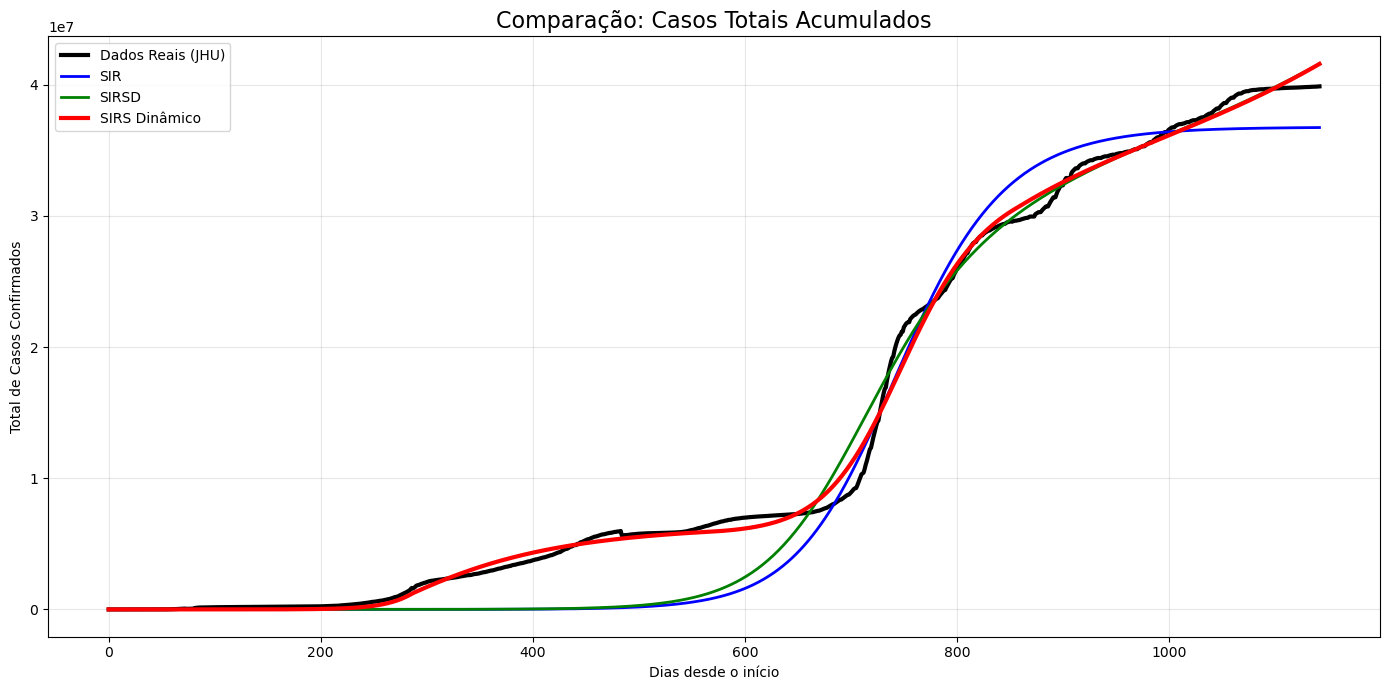

In [124]:
plt.figure(figsize=(14, 7))
plt.title("Comparação: Casos Totais Acumulados", fontsize=16)

# Dados reais
plt.plot(x_days, y_real_acc, color='black', label='Dados Reais (JHU)', alpha=1, linewidth=3)

# Modelos
plt.plot(x_days, C_sir, label='SIR', linestyle='-', color='blue', linewidth=2)
plt.plot(x_days, C_sirsd, label='SIRSD', linestyle='-', color='green', linewidth=2)
plt.plot(x_days, C_dyn, label='SIRS Dinâmico', color='red', linewidth=3)

plt.ylabel("Total de Casos Confirmados")
plt.xlabel("Dias desde o início")
plt.legend()
plt.grid(True, alpha=0.3)
plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

plt.tight_layout()
plt.show()

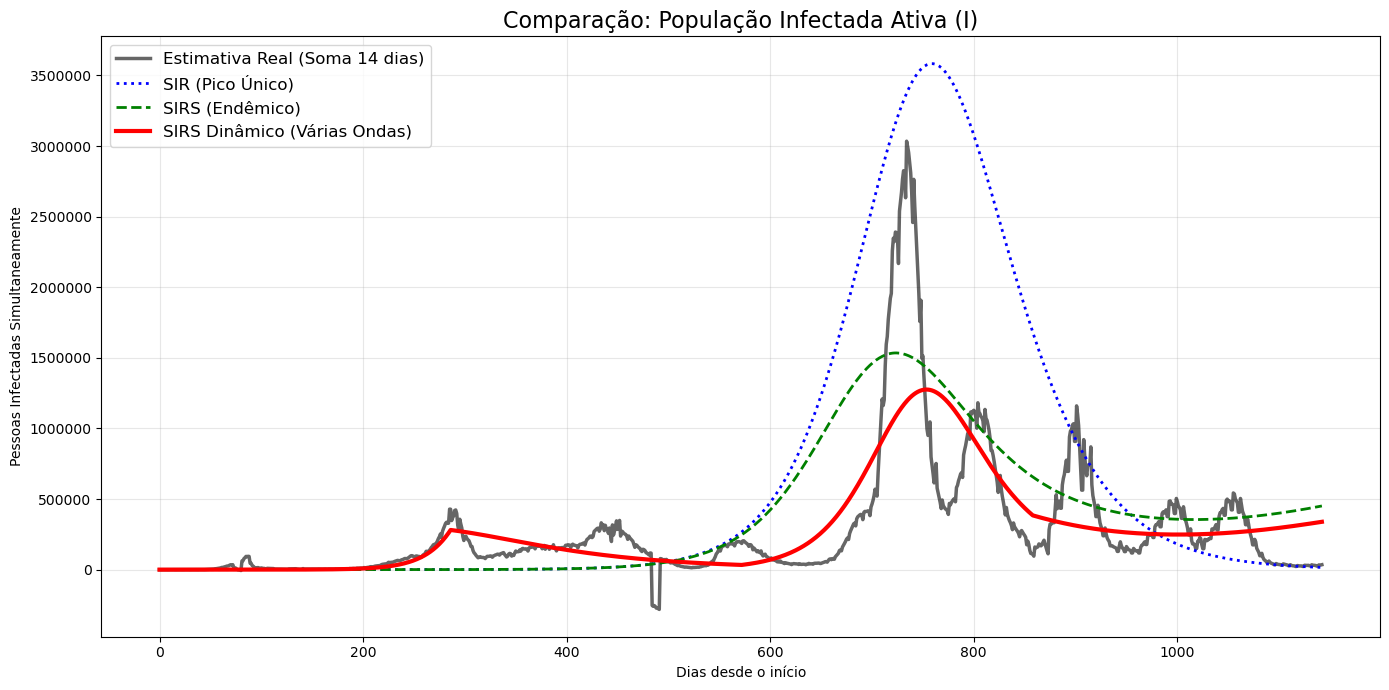

In [125]:

plt.figure(figsize=(14, 7))
plt.title("Comparação: População Infectada Ativa (I)", fontsize=16)



plt.plot(x_days, y_real_active, color='black', alpha=0.6, label='Estimativa Real (Soma 14 dias)', linewidth=2.5)
# plt.fill_between(x_days, y_real_active, color='black', alpha=0.1)

# 2. OS MODELOS
plt.plot(x_days, I_sir, label='SIR (Pico Único)', linestyle=':', color='blue', linewidth=2)
plt.plot(x_days, I_sirsd, label='SIRS (Endêmico)', linestyle='--', color='green', linewidth=2)
plt.plot(x_days, I_dyn, label='SIRS Dinâmico (Várias Ondas)', color='red', linewidth=3) # Destaque no dinâmico

# Detalhes
plt.ylabel("Pessoas Infectadas Simultaneamente")
plt.xlabel("Dias desde o início")
plt.legend(loc='upper left', fontsize=12)
plt.grid(True, alpha=0.3)
plt.ticklabel_format(style='plain', axis='y') # Remove notação científica (1e6)

plt.tight_layout()
plt.show()

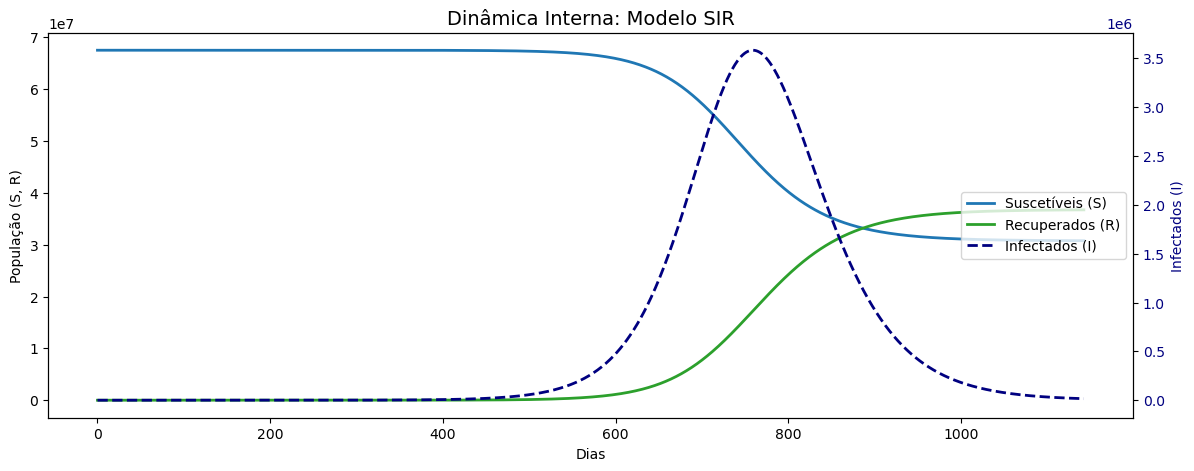

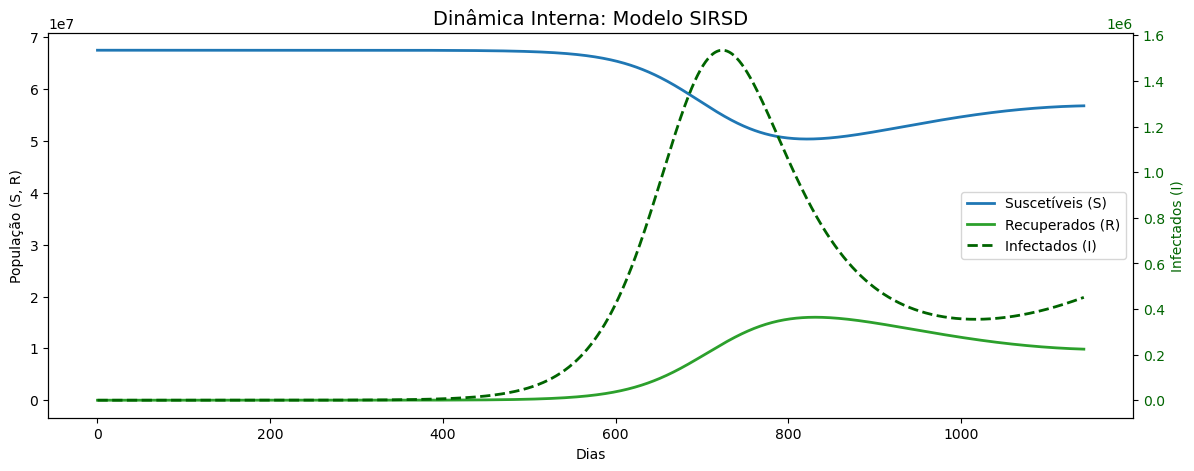

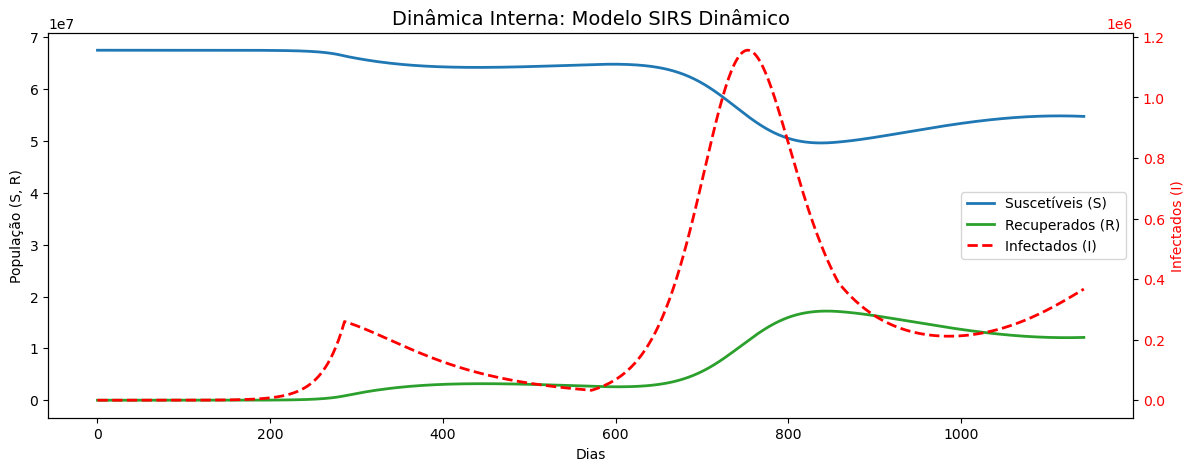

In [109]:
def plot_dynamics(model_name, S, I, R, color_i):
    fig, ax1 = plt.subplots(figsize=(14, 5))
    ax1.set_title(f"Dinâmica Interna: {model_name}", fontsize=14)
    
    # Eixo Esquerdo: S e R
    ax1.set_xlabel("Dias")
    ax1.set_ylabel("População (S, R)", color='black')
    line1, = ax1.plot(x_days, S, label='Suscetíveis (S)', color='tab:blue', linewidth=2)
    line2, = ax1.plot(x_days, R, label='Recuperados (R)', color='tab:green', linewidth=2)
    
    # Eixo Direito: I
    ax2 = ax1.twinx()
    line3, = ax2.plot(x_days, I, label='Infectados (I)', color=color_i, linewidth=2, linestyle='--')
    ax2.set_ylabel("Infectados (I)", color=color_i)
    ax2.tick_params(axis='y', labelcolor=color_i)
    
    # Legenda Unificada
    lines = [line1, line2, line3]
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='center right')
    
    plt.show()

plot_dynamics("Modelo SIR", S_sir, I_sir, R_sir, 'navy')
plot_dynamics("Modelo SIRSD", S_sirsd, I_sirsd, R_sirsd, 'darkgreen')
plot_dynamics("Modelo SIRS Dinâmico", S_dyn, I_dyn, R_dyn, 'red')